---
# **3. ARBOLADO**

**Objetivo:** medir cuánto arbolado tiene cada barrio (calle, zonas y parques), su tamaño y sus especies.

**Entradas:**
- En **`data/raw`**: `OD_Arbrat_Viari_BCN.csv`, `OD_Arbrat_Zona_BCN.csv` y `OD_Arbrat_Parcs_BCN.csv`.
- En **`data/processed`**: `barrios_base.gpkg` (cuaderno 1).

**Fuente y año:** Open Data BCN (Ajuntament de Barcelona). El último registro de plantación es de octubre de 2026.

**Salida** (en `data/processed`): `arbolado_por_barrio.csv`, una fila por barrio con `codi_barri` y las variables de arbolado.

**Limitaciones:**
- Solo cuenta el arbolado municipal: no incluye jardines privados ni bosque natural (Collserola).
- La categoría del árbol es una aproximación al tamaño (tronco), no a la copa.
- Las palmeras dan poca sombra y se cuentan aparte.
---

## Metodología previa: de dónde salen los datos

### A. ¿De dónde proceden?
Los datos vienen del **inventario de arbolado del Ayuntamiento de Barcelona**, publicado en el portal Open Data BCN en tres conjuntos de datos que se complementan:
- **Arbrat viari:** los árboles de las calles.
- **Arbrat zona:** los de plazas, jardineras y pequeños espacios ajardinados.
- **Arbrat parcs:** los de los parques.

Los descargamos en formato CSV (2026). Cada fila es **un árbol o una palmera**.

### B. ¿Qué información trae cada árbol?
| Columna | Qué contiene |
|---|---|
| `codi` | Identificador único del árbol |
| `x_etrs89`, `y_etrs89` | Posición en metros (ETRS89 UTM 31N, como los edificios) |
| `latitud`, `longitud` | Posición en grados |
| `tipus_element` | Árbol o palmera |
| `cat_nom_cientific` | Especie (nombre científico) |
| `categoria_arbrat` | Categoría (EXEMPLAR, PRIMERA, SEGONA, TERCERA), según el tronco |
| `data_plantacio` | Fecha de plantación |
| `codi_barri`, `nom_barri` | Barrio donde está el árbol |


In [37]:
from google.colab import drive
drive.mount('/content/drive')

CARPETA = '/content/drive/MyDrive/proyectofinal_ITAcademy/'
RAW = CARPETA + 'data/raw/'                           # Ruta limpia a la carpeta de datos originales
PROCESSED = CARPETA + 'data/processed/'              # Ruta limpia a la carpeta de procesados

import os
os.makedirs(PROCESSED, exist_ok=True)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


 Cargamos las librerías: **pandas** trabaja con tablas, **geopandas** es pandas con mapas y **matplotlib** dibuja gráficos.

In [38]:
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt

pd.set_option('display.max_columns', None)    # que pandas enseñe todas las columnas

## 1. Cargar los datos
Son tres tablas normales (CSV), no mapas. Las cargamos en un bucle para no repetir código y las guardamos en un diccionario: `tablas['viario']`, `tablas['zona']` y `tablas['parque']`.

In [39]:
archivos = {
    'viario': 'OD_Arbrat_Viari_BCN.csv',
    'zona': 'OD_Arbrat_Zona_BCN.csv',
    'parque': 'OD_Arbrat_Parcs_BCN.csv',
}

tablas = {}
for nombre, archivo in archivos.items():
    # encoding='utf-8-sig' evita símbolos raros en los acentos
    tablas[nombre] = pd.read_csv(RAW + archivo, encoding='utf-8-sig', low_memory=False)
    print(nombre, tablas[nombre].shape)

viario (145397, 22)
zona (44012, 22)
parque (33328, 22)


## 2. Inspección de los datos

### 2.1 Primeras filas

In [40]:
display(tablas['viario'].head(3))
print()
columnas = [set(t.columns) for t in tablas.values()]
print('Los tres archivos tienen las mismas columnas:', columnas[0] == columnas[1] == columnas[2])

,codi,x_etrs89,y_etrs89,latitud,longitud,tipus_element,espai_verd,adreca,cat_especie_id,cat_nom_cientific,cat_nom_castella,cat_nom_catala,categoria_arbrat,data_plantacio,tipus_aigua,tipus_reg,geom,catalogacio,codi_barri,nom_barri,codi_districte,nom_districte
0,0000423AR,430250.886,4587703.209,41.437872,2.165110,ARBRE VIARI,"Central de Nou Barris, Parc","Pg Fabra i Puig, 423",108,Pinus pinea,Pino piñonero,Pi pinyoner; pi pinyer,EXEMPLAR,NaN,NaN,GOTEIG AVARIAT,POINT (430250.886125371 4587703.20870032),NaN,48.0,LA GUINEUETA,8.0,NOU BARRIS
1,0000692AR,430783.470,4587491.937,41.436015,2.171508,PALMERA VIARI,"Central de Nou Barris, Parc","C\ Doctor Pi i Molist, 117",47,Phoenix canariensis,Palmera canaria,Palmera de Canaries; palmera de Canàries,TERCERA,NaN,NaN,ASPERSIÓ,POINT (430783.470348079 4587491.93733177),NaN,48.0,LA GUINEUETA,8.0,NOU BARRIS
2,0001110AR,430198.143,4587545.750,41.436449,2.164497,ARBRE VIARI,"Central de Nou Barris, Parc","Pg Fabra i Puig, 438",2336,Fraxinus angustifolia 'Raywood',-,-,PRIMERA,2019-10-31,NaN,GOTEIG AVARIAT,POINT (430198.143308265 4587545.7497126),NaN,47.0,CAN PEGUERA,8.0,NOU BARRIS



Los tres archivos tienen las mismas columnas: True


**Qué mirar:** cada fila es **un árbol**. Las columnas más importantes son:

- `codi`: Identificador único del árbol
- `x_etrs89`, `y_etrs89`: Posición en metros (sistema ETRS89 UTM 31N, el mismo de los edificios)
- `latitud`, `longitud`: Posición en grados
- `tipus_element`: Tipo: árbol o palmera, de calle, de zona o de parque
- `cat_nom_cientific`: Especie (nombre científico)
- `categoria_arbrat`: Categoría del árbol (EXEMPLAR, PRIMERA, SEGONA, TERCERA)
- `data_plantacio`: Fecha de plantación
- `codi_barri`, `nom_barri`: El barrio donde está el árbol, ya asignado por el Ayuntamiento

### 2.2 Tipos de datos

In [41]:
tablas['viario'].info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 145397 entries, 0 to 145396
Data columns (total 22 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   codi               145397 non-null  object 
 1   x_etrs89           145397 non-null  float64
 2   y_etrs89           145397 non-null  float64
 3   latitud            145397 non-null  float64
 4   longitud           145397 non-null  float64
 5   tipus_element      145397 non-null  object 
 6   espai_verd         34168 non-null   object 
 7   adreca             145397 non-null  object 
 8   cat_especie_id     145397 non-null  int64  
 9   cat_nom_cientific  145397 non-null  object 
 10  cat_nom_castella   142560 non-null  object 
 11  cat_nom_catala     142246 non-null  object 
 12  categoria_arbrat   145386 non-null  object 
 13  data_plantacio     32142 non-null   object 
 14  tipus_aigua        7959 non-null    object 
 15  tipus_reg          145355 non-null  object 
 16  ge

### 2.3 Valores vacíos y duplicados

In [42]:
vacios = pd.DataFrame({nombre: t.isna().sum() for nombre, t in tablas.items()})
display(vacios[vacios.sum(axis=1) > 0])

print('Identificadores (codi) repetidos dentro de cada archivo:')
for nombre, t in tablas.items():
    print('  ', nombre, t['codi'].duplicated().sum())

,viario,zona,parque
espai_verd,111229,2277,288
cat_nom_castella,2837,989,347
cat_nom_catala,3151,1090,381
categoria_arbrat,11,10,23
data_plantacio,113255,38235,31168
tipus_aigua,137438,40081,31983
tipus_reg,42,19,1
catalogacio,144714,43769,33120
codi_barri,8,6,0
nom_barri,8,6,0


Identificadores (codi) repetidos dentro de cada archivo:
   viario 0
   zona 0
   parque 0


**Qué mirar:**

- `codi_barri` tiene muy pocos vacíos: son árboles sin barrio asignado.
- No hay duplicados.

### 2.4 Categorías

In [43]:
for nombre, t in tablas.items():
    print('---', nombre)
    print(t['tipus_element'].value_counts().to_dict())
    print(t['categoria_arbrat'].value_counts(dropna=False).to_dict())

--- viario
{'ARBRE VIARI': 140612, 'PALMERA VIARI': 4785}
{'SEGONA': 59811, 'TERCERA': 36099, 'PRIMERA': 30815, 'EXEMPLAR': 18661, nan: 11}
--- zona
{'ARBRE ZONA': 42267, 'PALMERA ZONA': 1745}
{'SEGONA': 18774, 'PRIMERA': 9629, 'TERCERA': 9422, 'EXEMPLAR': 6177, nan: 10}
--- parque
{'ARBRE PARC': 30994, 'PALMERA PARC': 2334}
{'SEGONA': 13855, 'TERCERA': 7519, 'PRIMERA': 6721, 'EXEMPLAR': 5210, nan: 23}


Hay árboles y palmeras. Las **palmeras dan muy poca sombra**, así que las vamos a contar aparte.

La columna `categoria_arbrat` (EXEMPLAR, PRIMERA, SEGONA, TERCERA) es la clasificación oficial de Parques y Jardines del Ayuntamiento de Barcelona y hacen referencia principalmente al tamaño, edad y características de desarrollo del árbol:

- **PRIMERA (Primera categoría)**: Árboles recién plantados, jóvenes o de tamaño pequeño. Tienen pocos años de vida y su copa y tronco aún se están desarrollando. *Perímetro tronco: Hasta 40 cm*.

- **SEGONA (Segunda categoría)**: Árboles de tamaño mediano o en fase de maduración. Ya están establecidos pero aún no han alcanzado su máximo potencial. *Perímetro tronco: de 40 a 80 cm*.

- **TERCERA (Tercera categoría)**: Árboles grandes o plenamente desarrollados. Son árboles maduros que ya han alcanzado el tamaño y la copa habituales para su especie en un entorno urbano. *Perímetro tronco: más de 80 cm*.

- **EXEMPLAR (Ejemplar)**: Son árboles singulares o de gran valor histórico, botánico o de tamaño excepcional. Se consideran de especial protección debido a su edad, espectacularidad o interés público.

Hay 11 árboles en viario, 10 en zona y 23 en parque que no tienen una categoría asignada.

### 2.5 Valores raros: especies, posiciones y fechas

In [44]:
for nombre, t in tablas.items():
    print('---', nombre)
    print('Especies distintas:', t['cat_nom_cientific'].nunique())
    print('Posición x entre', round(t['x_etrs89'].min()), 'y', round(t['x_etrs89'].max()))
    print('Posición y entre', round(t['y_etrs89'].min()), 'y', round(t['y_etrs89'].max()))
    fechas = pd.to_datetime(t['data_plantacio'], errors='coerce')
    print('Fechas de plantación: de', fechas.min().date(), 'a', fechas.max().date())

--- viario
Especies distintas: 288
Posición x entre 423866 y 435038
Posición y entre 4577401 y 4590845
Fechas de plantación: de 2001-01-01 a 2026-10-30
--- zona
Especies distintas: 339
Posición x entre 424051 y 435229
Posición y entre 4577423 y 4591006
Fechas de plantación: de 2007-02-22 a 2026-10-30
--- parque
Especies distintas: 386
Posición x entre 424260 y 435347
Posición y entre 4578013 y 4590600
Fechas de plantación: de 2008-03-14 a 2026-10-29


Hay fechas de plantación **absurdas** (por ejemplo, del año 13). Son errores del inventario, y otro motivo para no usar esa columna.

La fecha más reciente es de octubre de 2026: la fuente está actualizada.

In [45]:
# Resumen: Comprobación de los datos
total_arboles = 0
print("1. TOTAL DE ÁRBOLES:")
for nombre, t in tablas.items():
    cant = len(t)
    total_arboles += cant
    print(f"  - {nombre.capitalize()}: {cant:,} árboles")
print(f"  - Total global: {total_arboles:,} árboles\n")

print("2. ÁRBOLES SIN BARRIO (Valores nulos en 'nom_barri'):")
for nombre, t in tablas.items():
    nulos = t['nom_barri'].isna().sum()
    print(f"  - {nombre.capitalize()}: {nulos}")
print()

print("3. PALMERAS VS ÁRBOLES (columna 'tipus_element'):")
for nombre, t in tablas.items():
    palmeras = t['tipus_element'].str.contains('PALMERA', case=False, na=False).sum()
    arboles = t['tipus_element'].str.contains('ARBRE', case=False, na=False).sum()
    print(f"  - {nombre.capitalize()}: {palmeras:,} palmeras y {arboles:,} árboles")
print()

1. TOTAL DE ÁRBOLES:
  - Viario: 145,397 árboles
  - Zona: 44,012 árboles
  - Parque: 33,328 árboles
  - Total global: 222,737 árboles

2. ÁRBOLES SIN BARRIO (Valores nulos en 'nom_barri'):
  - Viario: 8
  - Zona: 6
  - Parque: 0

3. PALMERAS VS ÁRBOLES (columna 'tipus_element'):
  - Viario: 4,785 palmeras y 140,612 árboles
  - Zona: 1,745 palmeras y 42,267 árboles
  - Parque: 2,334 palmeras y 30,994 árboles



## 3. Limpieza

### 3.1 Unimos las tres tablas en una sola

Pegamos una tabla debajo de otra con `concat`, y añadimos una columna `origen` para saber de qué archivo viene cada árbol.

In [46]:
arboles = pd.concat(
    [t.assign(origen=nombre) for nombre, t in tablas.items()],
    ignore_index=True)

print('Árboles en total:', len(arboles), '(esperado 222.737)')
print('Identificadores repetidos entre archivos:', arboles['codi'].duplicated().sum())

Árboles en total: 222737 (esperado 222.737)
Identificadores repetidos entre archivos: 0


### 3.2 Nos quedamos solo con lo que necesitamos y ponemos nombres claros

In [47]:
# Filtramos solo las columnas que necesitamos
arboles = arboles[['codi', 'origen', 'tipus_element', 'categoria_arbrat', 'cat_nom_cientific', 'codi_barri', 'x_etrs89', 'y_etrs89']].copy()

# Renombramos las columnas
arboles = arboles.rename(columns={
    'codi': 'codi_arboles',
    'origen': 'origen_arboles',
    'cat_nom_cientific': 'nom_cientific'
})

display(arboles.head(3))

,codi_arboles,origen_arboles,tipus_element,categoria_arbrat,nom_cientific,codi_barri,x_etrs89,y_etrs89
0,0000423AR,viario,ARBRE VIARI,EXEMPLAR,Pinus pinea,48.0,430250.886,4587703.209
1,0000692AR,viario,PALMERA VIARI,TERCERA,Phoenix canariensis,48.0,430783.470,4587491.937
2,0001110AR,viario,ARBRE VIARI,PRIMERA,Fraxinus angustifolia 'Raywood',47.0,430198.143,4587545.750


### 3.3 Tratamos los árboles sin barrio

Hay 14 árboles sin barrio, pero sí tienen sus coordenadas, por lo que podemos sacar el barrio al que pertenecen en vez de descartarlos.

In [48]:
sin_barrio = arboles[arboles['codi_barri'].isna()]
print('Árboles sin barrio:', len(sin_barrio))
display(sin_barrio.head(14))

Árboles sin barrio: 14


,codi_arboles,origen_arboles,tipus_element,categoria_arbrat,nom_cientific,codi_barri,x_etrs89,y_etrs89
11986,0037796AR,viario,ARBRE VIARI,TERCERA,Celtis australis,NaN,434080.679,4586006.595
12274,0038124AR,viario,ARBRE VIARI,TERCERA,Celtis australis,NaN,434082.551,4585999.778
125762,0240094AR,viario,PALMERA VIARI,SEGONA,Washingtonia filifera,NaN,427617.436,4579203.335
130394,0286581AR,viario,ARBRE VIARI,SEGONA,Styphnolobium japonicum,NaN,427688.339,4579311.265
138630,0315892AR,viario,ARBRE VIARI,SEGONA,Fraxinus excelsior,NaN,433892.178,4586250.262
143114,0337504AR,viario,ARBRE VIARI,TERCERA,Ailanthus altissima,NaN,434626.579,4585348.315
143117,0337507AR,viario,ARBRE VIARI,SEGONA,Cercis siliquastrum,NaN,434628.257,4585360.359
144783,0345745AR,viario,ARBRE VIARI,SEGONA,Brachychiton acerifolius,NaN,434696.183,4585291.310
152614,0232355AR,zona,ARBRE ZONA,SEGONA,Jacaranda mimosifolia,NaN,425397.601,4581145.080
152688,0234043AR,zona,ARBRE ZONA,TERCERA,Jacaranda mimosifolia,NaN,425397.817,4581150.166


### 3.4 Recuperamos los barrios de los árboles sin asignar mediante análisis espacial

Los 14 árboles sin barrio asignado **sí tienen coordenadas**. Los convertimos en puntos geográficos y, con el mapa de límites de los barrios, les asignamos su barrio en lugar de descartarlos.

In [49]:
# Convertimos los 14 árboles sin barrio en un GeoDataFrame usando sus coordenadas UTM (ETRS89 / UTM 31N -> EPSG:25831)
puntos_sin_barrio = gpd.GeoDataFrame(
    sin_barrio,
    geometry=gpd.points_from_xy(sin_barrio['x_etrs89'], sin_barrio['y_etrs89']),
    crs="EPSG:25831"
)

print("Coordenadas de los árboles sin barrio listos para georreferenciar:")
display(puntos_sin_barrio[['codi_arboles', 'origen_arboles', 'geometry']])

Coordenadas de los árboles sin barrio listos para georreferenciar:


,codi_arboles,origen_arboles,geometry
11986,0037796AR,viario,POINT (434080.679 4586006.595)
12274,0038124AR,viario,POINT (434082.551 4585999.778)
125762,0240094AR,viario,POINT (427617.436 4579203.335)
130394,0286581AR,viario,POINT (427688.339 4579311.265)
138630,0315892AR,viario,POINT (433892.178 4586250.262)
143114,0337504AR,viario,POINT (434626.579 4585348.315)
143117,0337507AR,viario,POINT (434628.257 4585360.359)
144783,0345745AR,viario,POINT (434696.183 4585291.31)
152614,0232355AR,zona,POINT (425397.601 4581145.08)
152688,0234043AR,zona,POINT (425397.817 4581150.166)


Cargamos el Dataset de barrios para poder hacer el cruce

In [50]:
barrios = gpd.read_file(PROCESSED + 'barrios_base.gpkg')

print('Sistema de coordenadas:', barrios.crs)
print('Barrios cargados:', len(barrios))

Sistema de coordenadas: EPSG:25831
Barrios cargados: 73


Miramos el nombre de las columnas del Dataset barrios

In [51]:
print("Columnas del mapa de barrios original:")
print(list(barrios.columns))

Columnas del mapa de barrios original:
['codi_barri', 'nom_barri', 'codi_districte', 'nom_districte', 'area_km2', 'geometry']


Realizamos un cruce de tipo izquierdo (`how='left'`) para mantener los 14 árboles en la lista y poder ver cuáles obtienen barrio y cuáles se quedan como `NaN` por estar fuera de los límites de Barcelona.

In [52]:
# Eliminamos la columna vacía 'codi_barri' de los puntos antes del cruce
puntos_sin_barrio_limpios = puntos_sin_barrio.drop(columns=['codi_barri'])

# Hacemos el cruce espacial
arboles_recuperados = gpd.sjoin(puntos_sin_barrio_limpios, barrios, how="left", predicate="within")

# Mostramos el resultado
display(arboles_recuperados[['codi_arboles', 'origen_arboles', 'codi_barri', 'nom_barri']])

,codi_arboles,origen_arboles,codi_barri,nom_barri
11986,0037796AR,viario,73.0,la Verneda i la Pau
12274,0038124AR,viario,73.0,la Verneda i la Pau
125762,0240094AR,viario,NaN,NaN
130394,0286581AR,viario,13.0,la Marina de Port
138630,0315892AR,viario,73.0,la Verneda i la Pau
143114,0337504AR,viario,70.0,el Besòs i el Maresme
143117,0337507AR,viario,NaN,NaN
144783,0345745AR,viario,70.0,el Besòs i el Maresme
152614,0232355AR,zona,20.0,la Maternitat i Sant Ramon
152688,0234043AR,zona,20.0,la Maternitat i Sant Ramon


### 3.4.1 Devolvemos los barrios recuperados a la tabla de árboles

En la celda anterior hemos calculado el barrio de los 14 árboles, pero ese resultado se queda en `arboles_recuperados`: todavía no lo hemos pasado a la tabla `arboles`. Lo hacemos ahora. Con `map` buscamos el barrio de cada árbol por su código, y solo rellenamos los árboles que tenían el barrio vacío.

In [53]:
recuperados = arboles_recuperados.drop_duplicates(subset='codi_arboles').dropna(subset=['codi_barri'])
recuperados = recuperados.set_index('codi_arboles')['codi_barri']

sin = arboles['codi_barri'].isna()                                              # los árboles que tenían el barrio vacío
arboles.loc[sin, 'codi_barri'] = arboles.loc[sin, 'codi_arboles'].map(recuperados)

print('Árboles que tenían el barrio vacío:', sin.sum())
print('Recuperados con el mapa:', sin.sum() - arboles['codi_barri'].isna().sum())
print('Siguen sin barrio:', arboles['codi_barri'].isna().sum())

Árboles que tenían el barrio vacío: 14
Recuperados con el mapa: 12
Siguen sin barrio: 2


Quitamos los árboles que siguen sin barrio tras la recuperación (no caen dentro de ningún barrio de nuestro mapa). Hay que hacerlo **antes** de convertir a entero, porque un entero no admite valores vacíos.

In [54]:
arboles = arboles.dropna(subset=['codi_barri']).copy()

print("Árboles sin barrio restantes tras la limpieza final:", arboles['codi_barri'].isna().sum())
print("Total de árboles final en el dataset:", len(arboles))

Árboles sin barrio restantes tras la limpieza final: 0
Total de árboles final en el dataset: 222735


Convertimos la columna `codi_barri` a tipo entero

In [55]:
arboles['codi_barri'] = arboles['codi_barri'].astype(int)

# Verificamos el cambio de tipo de datos y una muestra
print(arboles['codi_barri'].dtype)
display(arboles[['codi_arboles', 'codi_barri']].head())

int64


,codi_arboles,codi_barri
0,0000423AR,48
1,0000692AR,48
2,0001110AR,47
3,0001112AR,48
4,0001113AR,48


### 3.5 Marcamos las palmeras

In [56]:
arboles['es_palmera'] = arboles['tipus_element'].fillna('').str.startswith('PALMERA')
print(arboles['es_palmera'].value_counts())

es_palmera
False    213872
True       8863
Name: count, dtype: int64


## 4. Contamos los árboles por barrio

Usamos `pivot_table`: una fila por barrio, una columna por cada tipo de arbolado y dentro, el número de árboles.

In [57]:
por_origen = arboles.pivot_table(index='codi_barri', columns='origen_arboles', values='codi_arboles', aggfunc='count', fill_value=0)
por_origen.columns = ['n_' + c for c in por_origen.columns]       # n_parque, n_viario, n_zona
por_origen['n_arboles'] = por_origen.sum(axis=1)                  # total de árboles del barrio
por_origen = por_origen.reset_index()

palmeras = arboles[arboles['es_palmera']].groupby('codi_barri').size().rename('n_palmeras').reset_index()
por_origen = por_origen.merge(palmeras, on='codi_barri', how='left')

display(por_origen.head())

,codi_barri,n_parque,n_viario,n_zona,n_arboles,n_palmeras
0,1,0,1677,332,2009,123.0
1,2,0,689,108,797,185.0
2,3,708,2032,85,2825,583.0
3,4,1338,1881,8,3227,321.0
4,5,430,2465,295,3190,173.0


### 4.1 Unimos con el esqueleto de barrios y calculamos la densidad

Traemos el nombre, el distrito y la superficie de cada barrio y calculamos los **árboles por km²**. Usamos `how='left'` para conservar los **73 barrios**.

In [58]:
tabla = barrios[['codi_barri', 'nom_barri', 'nom_districte', 'area_km2']].merge(por_origen, on='codi_barri', how='left')

columnas_conteo = ['n_parque', 'n_viario', 'n_zona', 'n_arboles', 'n_palmeras']
tabla[columnas_conteo] = tabla[columnas_conteo].fillna(0).astype(int)

tabla['arboles_por_km2'] = tabla['n_arboles'] / tabla['area_km2']
display(tabla.head())

,codi_barri,nom_barri,nom_districte,area_km2,n_parque,n_viario,n_zona,n_arboles,n_palmeras,arboles_por_km2
0,1,el Raval,Ciutat Vella,1.100286,0,1677,332,2009,123,1825.888680
1,2,el Barri Gòtic,Ciutat Vella,0.815594,0,689,108,797,185,977.201967
2,3,la Barceloneta,Ciutat Vella,1.179382,708,2032,85,2825,583,2395.322396
3,4,"Sant Pere, Santa Caterina i la Ribera",Ciutat Vella,1.109669,1338,1881,8,3227,321,2908.074967
4,5,el Fort Pienc,Eixample,0.929356,430,2465,295,3190,173,3432.485240


### 4.2 ¿Mezclar o separar? Árboles de calle frente a parques y zonas

Hasta ahora hemos sumado los tres tipos en `n_arboles`. Pero **no todos los árboles hacen lo mismo**:
- Los **árboles de calle** dan sombra directamente donde camina la gente. Además, son los que el Ayuntamiento puede plantar para cambiar una calle concreta.
- Los de **parques y zonas** enfrían el propio parque y algo su entorno, pero no la calle de al lado.

Si usamos solo el total, un barrio con un parque grande parece muy verde aunque sus calles estén desnudas. Para que los datos no se deformen, **mantenemos los tres tipos por separado** (ya los tenemos: `n_viario`, `n_zona` y `n_parque`) y calculamos la densidad de cada uno.

In [59]:
tabla['viario_por_km2'] = tabla['n_viario'] / tabla['area_km2']
tabla['zona_por_km2'] = tabla['n_zona'] / tabla['area_km2']
tabla['parque_por_km2'] = tabla['n_parque'] / tabla['area_km2']
tabla['verde_no_calle_por_km2'] = tabla['zona_por_km2'] + tabla['parque_por_km2']

display(tabla[['viario_por_km2', 'zona_por_km2', 'parque_por_km2']].median().round(0).to_frame('mediana por km2'))

,mediana por km2
viario_por_km2,2074.0
zona_por_km2,491.0
parque_por_km2,78.0


**Qué mirar:** las medianas (de los 73 barrios) son de unos **2.100 árboles por km² en las calles**, unos **500 en zonas** y menos de **100 en parques**. Los parques están muy concentrados en pocos barrios.

Ahora vamos a ver **cuánto cambia el orden de los barrios** según midamos el total o solo la calle.

In [60]:
tabla['posicion_total'] = tabla['arboles_por_km2'].rank(ascending=False).astype(int)     # 1 = el barrio con más árboles por km2
tabla['posicion_calle'] = tabla['viario_por_km2'].rank(ascending=False).astype(int)

ejemplos = ['la Salut', 'el Turó de la Peira', 'Sant Antoni', 'el Raval', 'Sant Pere, Santa Caterina i la Ribera']
display(tabla[tabla['nom_barri'].isin(ejemplos)][['nom_barri', 'arboles_por_km2', 'viario_por_km2', 'parque_por_km2', 'posicion_total', 'posicion_calle']].round(0))

,nom_barri,arboles_por_km2,viario_por_km2,parque_por_km2,posicion_total,posicion_calle
0,el Raval,1826.0,1524.0,0.0,65,53
3,"Sant Pere, Santa Caterina i la Ribera",2908.0,1695.0,1206.0,42,46
9,Sant Antoni,3232.0,3099.0,0.0,34,11
29,la Salut,5531.0,1319.0,3876.0,3,57
45,el Turó de la Peira,7329.0,2360.0,4317.0,1,29


**Qué mirar (valores aproximados):**
- **La Salut** es de los tres barrios con más árboles por km² en total, pero baja a la posición **57** si miramos solo la calle: siete de cada diez de sus árboles están en parques.
- **El Turó de la Peira** pasa del puesto 1 al 29.
- **Sant Antoni**, en el Eixample, hace lo contrario: del puesto 34 en total al 11 en la calle, porque no tiene árboles de parque pero sus calles sí están arboladas.
- **Sant Pere, Santa Caterina i la Ribera** parece tener un arbolado normal (unos 2.900 por km²), pero cuatro de cada diez árboles son de parques (sobre todo el de la Ciutadella): en la calle tiene unos 1.700, parecido al Raval (unos 1.500).

Si hubiéramos usado solo el total, habríamos deformado justo lo que el proyecto quiere medir: **cuánta sombra hay en las calles**. Por eso, en el análisis usaremos la densidad de **calle** y la de **parques y zonas** como variables distintas, y dejaremos el total solo como dato descriptivo.

### 4.3 Contamos los árboles de calle de cada tamaño, por barrio

No todos los árboles dan la misma sombra. Un árbol recién plantado cuenta igual que uno maduro, y no dan la misma sombra. La columna `categoria_arbrat` se basa en el **perímetro del tronco**: según un informe municipal, la primera categoría llega hasta 40 cm, la segunda va de 40 a 80 cm y la tercera supera los 80 cm. Los **EXEMPLAR** son ejemplares singulares.

Calculamos cuántos árboles de cada categoría hay en cada barrio, sin contar las palmeras (dan poca sombra) ni los pocos árboles sin categoría. Con ellos calculamos también los árboles **grandes** (tercera categoría y ejemplares), su porcentaje y su densidad por km².

In [61]:
calle = arboles[(arboles['origen_arboles'] == 'viario') & (~arboles['es_palmera'])].copy()
print('Árboles de calle (sin palmeras):', len(calle), '| sin categoría:', calle['categoria_arbrat'].isna().sum())
calle = calle.dropna(subset=['categoria_arbrat'])

por_tamano = calle.pivot_table(index='codi_barri', columns='categoria_arbrat', values='codi_arboles', aggfunc='count', fill_value=0)
por_tamano = por_tamano.rename(columns={'PRIMERA': 'n_viario_primera', 'SEGONA': 'n_viario_segona',
                                        'TERCERA': 'n_viario_tercera', 'EXEMPLAR': 'n_viario_exemplar'}).reset_index()

columnas_tamano = ['n_viario_primera', 'n_viario_segona', 'n_viario_tercera', 'n_viario_exemplar']
tabla = tabla.merge(por_tamano, on='codi_barri', how='left')
tabla[columnas_tamano] = tabla[columnas_tamano].fillna(0).astype(int)

tabla['n_viario_arboles'] = tabla[columnas_tamano].sum(axis=1)                  # árboles de calle con categoría, sin palmeras
tabla['n_viario_grandes'] = tabla['n_viario_tercera'] + tabla['n_viario_exemplar']

for cat in ['primera', 'segona', 'tercera', 'exemplar', 'grandes']:
    tabla['pct_viario_' + cat] = tabla['n_viario_' + cat] / tabla['n_viario_arboles'] * 100

for cat in ['primera', 'segona', 'grandes']:
    tabla['viario_' + cat + '_por_km2'] = tabla['n_viario_' + cat] / tabla['area_km2']

display(tabla[['nom_barri', 'n_viario_primera', 'n_viario_segona', 'n_viario_tercera', 'n_viario_exemplar', 'n_viario_arboles']].head())

print('Árboles de calle con categoría (suma de los 4 tamaños):', tabla['n_viario_arboles'].sum())

Árboles de calle (sin palmeras): 140611 | sin categoría: 8


,nom_barri,n_viario_primera,n_viario_segona,n_viario_tercera,n_viario_exemplar,n_viario_arboles
0,el Raval,272,585,404,315,1576
1,el Barri Gòtic,183,150,69,121,523
2,la Barceloneta,303,771,291,162,1527
3,"Sant Pere, Santa Caterina i la Ribera",396,575,381,388,1740
4,el Fort Pienc,346,923,636,410,2315


Árboles de calle con categoría (suma de los 4 tamaños): 140603


**Qué mirar:** Dos barrios con los mismos árboles por km² pueden dar una sombra muy distinta si en uno son jóvenes y en el otro maduros. Es una variable que merece la pena probar en el modelo.

**Una limitación:** la categoría es una aproximación al tamaño del árbol (se basa en el tronco, no en la copa).

### 4.4 La composición de cada barrio

Un gráfico de barras apiladas enseña, para varios barrios, qué porcentaje de sus árboles de calle es de cada tamaño.

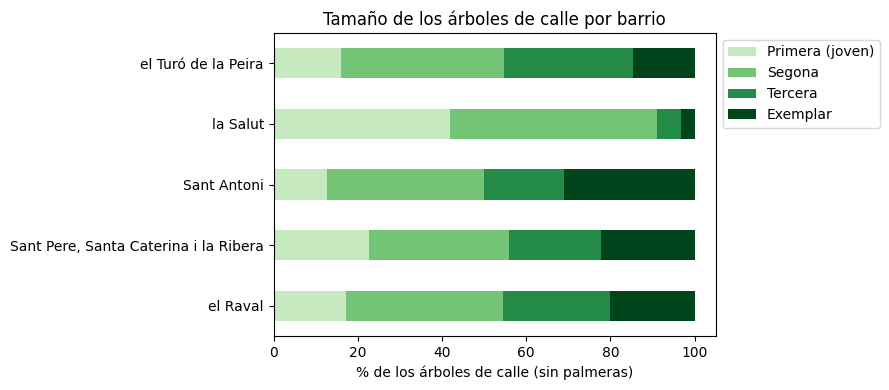

% de árboles de calle de tercera categoría o ejemplares, por barrio: mínimo 9.0 | mediana 34.2 | máximo 62.4


In [62]:
composicion = tabla[tabla['nom_barri'].isin(ejemplos)].set_index('nom_barri')[
    ['pct_viario_primera', 'pct_viario_segona', 'pct_viario_tercera', 'pct_viario_exemplar']]

composicion.plot(kind='barh', stacked=True, figsize=(9, 4), color=['#c7e9c0', '#74c476', '#238b45', '#00441b'])
plt.xlabel('% de los árboles de calle (sin palmeras)')
plt.ylabel('')
plt.legend(['Primera (joven)', 'Segona', 'Tercera', 'Exemplar'], loc='upper left', bbox_to_anchor=(1, 1))
plt.title('Tamaño de los árboles de calle por barrio')
plt.tight_layout()
plt.show()

print('% de árboles de calle de tercera categoría o ejemplares, por barrio: mínimo', round(tabla['pct_viario_grandes'].min(), 1),
      '| mediana', round(tabla['pct_viario_grandes'].median(), 1), '| máximo', round(tabla['pct_viario_grandes'].max(), 1))

**Qué mirar:** El porcentaje de árboles grandes varía mucho entre barrios, de un 9 % a más del 60 %. Por ejemplo, en **Sant Antoni** la mitad de los árboles de calle son de tercera categoría o ejemplares, mientras que en **La Salut** solo lo son el 9 % y el 42 % son de primera categoría (jóvenes).


### 4.5 Las especies de cada barrio

4.5.1 Primero, qué especies dominan en las calles de toda la ciudad (sin palmeras):

In [63]:
calle_sp = arboles[(arboles['origen_arboles'] == 'viario') & (~arboles['es_palmera'])].copy()

print('Especies distintas en las calles:', calle_sp['nom_cientific'].nunique())
top10 = (calle_sp['nom_cientific'].value_counts().head(10) / len(calle_sp) * 100).round(1)
display(top10.to_frame('% de los árboles de calle'))
print('Las 10 primeras suman:', round(top10.sum(), 1), '%')

Especies distintas en las calles: 275


,% de los árboles de calle
nom_cientific,
Platanus × acerifolia,28.5
Celtis australis,13.8
Styphnolobium japonicum,5.8
Tipuana tipu,4.7
Melia azedarach,4.5
Brachychiton populneus,3.7
Pyrus calleryana 'Chanticleer',2.5
Jacaranda mimosifolia,2.3
Ligustrum lucidum,2.3


Las 10 primeras suman: 70.1 %


**Qué mirar:** hay unas **275 especies** distintas, pero las 10 primeras suman el **70.1 %** y el plátano (*Platanus × acerifolia*) por sí solo, un **28,5 %**. Después vienen el almez (*Celtis australis*, 13.8 %) y el sófora (*Styphnolobium japonicum*, 5.8 %). Es una ciudad con **poca diversidad** en sus calles.

4.5.2 Ahora, por barrio: cuántas especies distintas hay, cuál es la dominante y qué parte del arbolado de calle representa.

In [64]:
n_especies = calle_sp.groupby('codi_barri')['nom_cientific'].nunique().rename('n_especies_viario').reset_index()
totales = calle_sp.groupby('codi_barri').size().rename('n_calle_total').reset_index()

conteo = calle_sp.groupby(['codi_barri', 'nom_cientific']).size().reset_index(name='n_dominante')
dominante = (conteo.sort_values('n_dominante', ascending=False)
                   .drop_duplicates(subset='codi_barri')
                   .rename(columns={'nom_cientific': 'especie_dominante'}))

resumen = dominante.merge(n_especies, on='codi_barri').merge(totales, on='codi_barri')
resumen['pct_especie_dominante'] = resumen['n_dominante'] / resumen['n_calle_total'] * 100

tabla = tabla.merge(resumen[['codi_barri', 'n_especies_viario', 'especie_dominante', 'pct_especie_dominante']], on='codi_barri', how='left')

print('Especies por barrio: mínimo', tabla['n_especies_viario'].min(), '| mediana', tabla['n_especies_viario'].median(), '| máximo', tabla['n_especies_viario'].max())
print('% de la especie dominante: mínimo', round(tabla['pct_especie_dominante'].min(), 1), '| mediana', round(tabla['pct_especie_dominante'].median(), 1), '| máximo', round(tabla['pct_especie_dominante'].max(), 1))
print()
print('Especie dominante en cuántos barrios:')
print(tabla['especie_dominante'].value_counts().head(6))

Especies por barrio: mínimo 19 | mediana 47.0 | máximo 80
% de la especie dominante: mínimo 12.6 | mediana 24.5 | máximo 52.9

Especie dominante en cuántos barrios:
especie_dominante
Platanus × acerifolia      42
Celtis australis            8
Styphnolobium japonicum     6
Brachychiton populneus      3
Melia azedarach             3
Ligustrum lucidum           2
Name: count, dtype: int64


### 4.6 Cuántos árboles de calle hay de cada tamaño

Cuatro mapas, uno por categoría, con la burbuja más grande donde hay más árboles. Usamos la misma escala en los cuatro para poder compararlos.

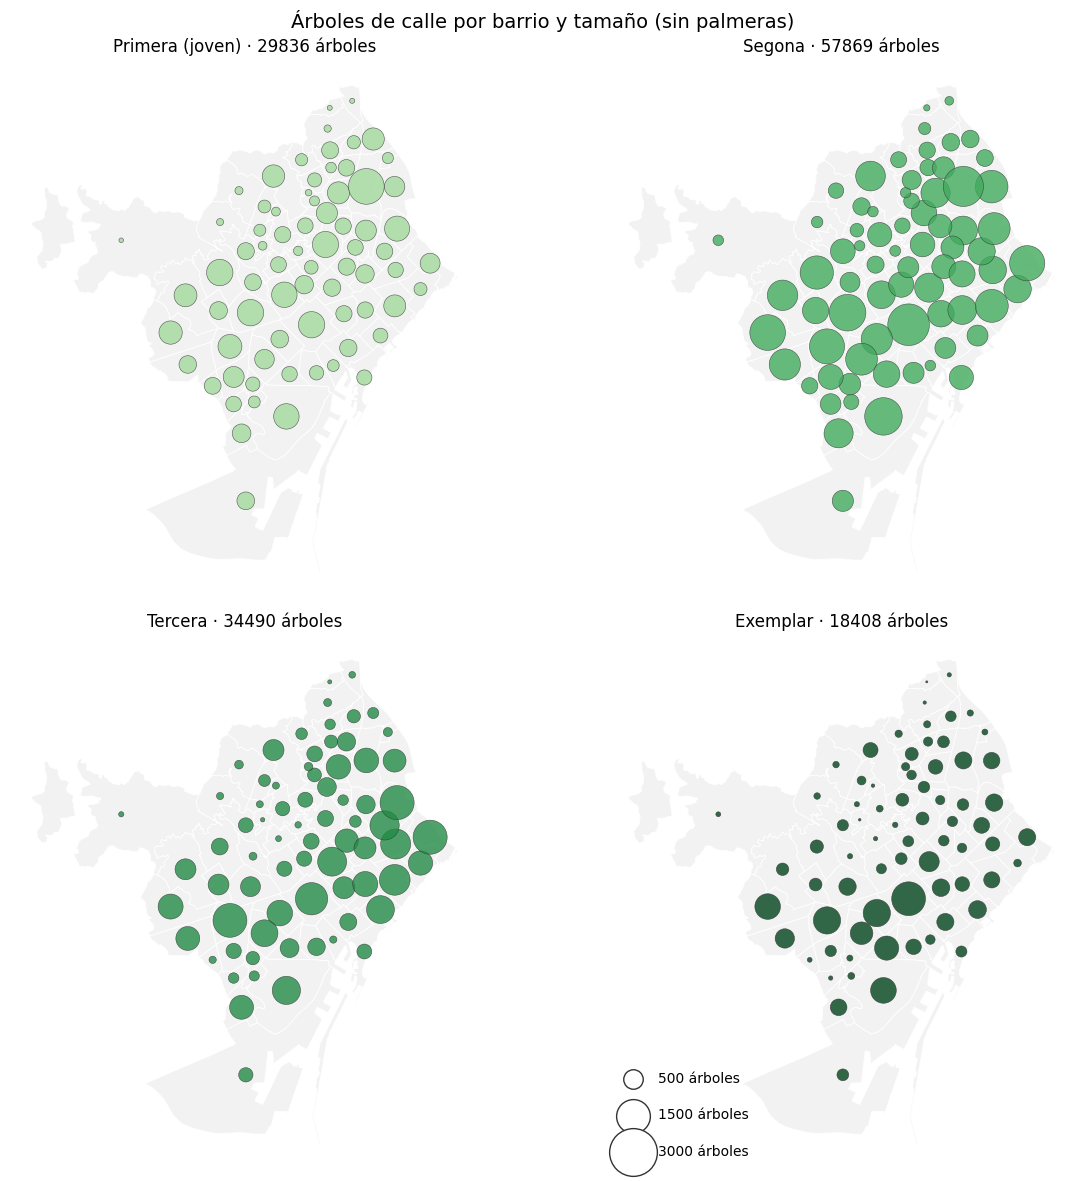

In [65]:
centros = barrios[['codi_barri', 'geometry']].copy()
centros['geometry'] = centros.geometry.centroid              # un punto en el centro de cada barrio
columnas_tamano = ['n_viario_primera', 'n_viario_segona', 'n_viario_tercera', 'n_viario_exemplar']
centros = centros.merge(tabla[['codi_barri', 'nom_barri', 'n_viario_arboles', 'especie_dominante'] + columnas_tamano], on='codi_barri')

categorias = [('n_viario_primera', 'Primera (joven)', '#a1d99b'), ('n_viario_segona', 'Segona', '#41ab5d'),
              ('n_viario_tercera', 'Tercera', '#238b45'), ('n_viario_exemplar', 'Exemplar', '#00441b')]
escala = 900 / centros[columnas_tamano].max().max()          # la misma escala para los cuatro mapas

fig, ejes = plt.subplots(2, 2, figsize=(13, 12))
for ax, (col, titulo, color) in zip(ejes.ravel(), categorias):
    barrios.plot(ax=ax, color='#f2f2f2', edgecolor='white', linewidth=0.6)
    ax.scatter(centros.geometry.x, centros.geometry.y, s=centros[col] * escala, color=color,
               edgecolor='#333333', linewidth=0.4, alpha=0.8)
    ax.set_title(titulo + ' · ' + str(int(centros[col].sum())) + ' árboles', fontsize=12)
    ax.axis('off')

for n in [500, 1500, 3000]:                                  # leyenda de tamaños
    ejes[1, 1].scatter([], [], s=n * escala, color='white', edgecolor='#333333', label=str(n) + ' árboles')
ejes[1, 1].legend(loc='lower left', frameon=False, labelspacing=1.6)
plt.suptitle('Árboles de calle por barrio y tamaño (sin palmeras)', fontsize=14)
plt.tight_layout()
plt.show()

**Qué mirar:** compara los cuatro mapas. Los árboles **jóvenes** (primera) y los **maduros** (tercera y ejemplares) no están repartidos igual.

Ahora, **qué especie domina en cada barrio**. El color es la especie dominante y el tamaño de la burbuja, el número de árboles de calle.

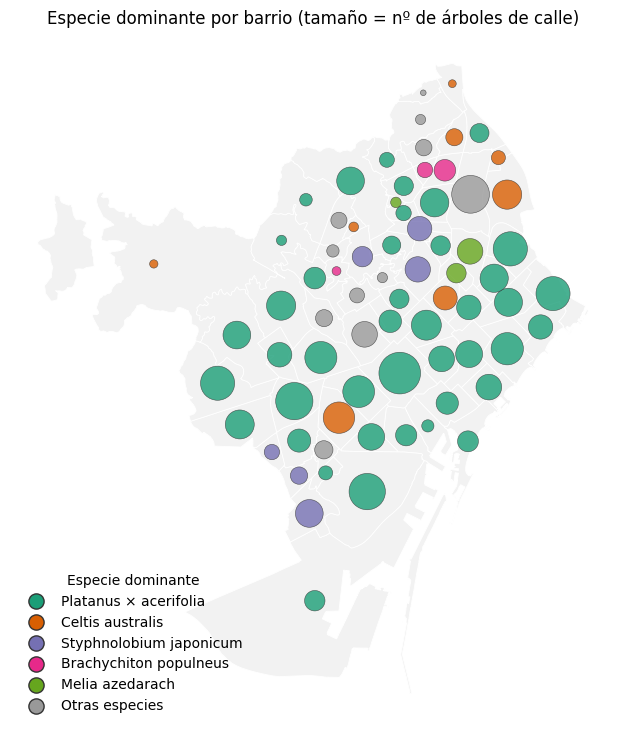

In [66]:
principales = tabla['especie_dominante'].value_counts().head(5).index.tolist()     # las 5 especies dominantes más frecuentes
paleta = ['#1b9e77', '#d95f02', '#7570b3', '#e7298a', '#66a61e']
color_de = dict(zip(principales, paleta))
colores = centros['especie_dominante'].map(color_de).fillna('#999999')           # el resto de especies, en gris

fig, ax = plt.subplots(figsize=(9, 9))
barrios.plot(ax=ax, color='#f2f2f2', edgecolor='white', linewidth=0.6)
ax.scatter(centros.geometry.x, centros.geometry.y, s=centros['n_viario_arboles'] / centros['n_viario_arboles'].max() * 900,
           c=colores, edgecolor='#333333', linewidth=0.4, alpha=0.8)
for especie, color in color_de.items():                                          # leyenda de colores
    ax.scatter([], [], s=120, color=color, edgecolor='#333333', label=especie)
ax.scatter([], [], s=120, color='#999999', edgecolor='#333333', label='Otras especies')
ax.legend(loc='lower left', frameon=False, title='Especie dominante')
ax.set_title('Especie dominante por barrio (tamaño = nº de árboles de calle)')
ax.axis('off')
plt.show()

**Qué mirar:** el plátano (el color más frecuente) domina en la mayor parte de la ciudad. Los barrios con otra especie dominante son los que tienen un arbolado distinto.

## 5. Comprobaciones

In [67]:
print('Códigos de barrio repetidos:', tabla['codi_barri'].duplicated().sum())
print('Filas:', len(tabla), '(esperado 73)')
print('Árboles sumando todos los barrios:', tabla['n_arboles'].sum())
print('Barrios sin ningún árbol de parque:', (tabla['n_parque'] == 0).sum())
print('Mediana de árboles por km2:', round(tabla['arboles_por_km2'].median(), 1))
print()
print('Los 5 barrios con más árboles por km2:')
display(tabla.sort_values('arboles_por_km2', ascending=False).head(5)[['nom_barri', 'n_arboles', 'arboles_por_km2']].round(1))
print('Los 5 barrios con menos árboles por km2:')
display(tabla.sort_values('arboles_por_km2').head(5)[['nom_barri', 'n_arboles', 'arboles_por_km2']].round(0))

Códigos de barrio repetidos: 0
Filas: 73 (esperado 73)
Árboles sumando todos los barrios: 222735
Barrios sin ningún árbol de parque: 21
Mediana de árboles por km2: 3156.3

Los 5 barrios con más árboles por km2:


,nom_barri,n_arboles,arboles_por_km2
45,el Turó de la Peira,2596,7328.9
47,la Guineueta,3731,6096.8
29,la Salut,3586,5530.6
71,Sant Martí de Provençals,3783,5154.0
44,Porta,4094,4892.3


Los 5 barrios con menos árboles por km2:


,nom_barri,n_arboles,arboles_por_km2
21,"Vallvidrera, el Tibidabo i les Planes",400,35.0
11,la Marina del Prat Vermell,1922,135.0
53,Torre Baró,607,348.0
38,Sant Genís dels Agudells,914,543.0
55,Vallbona,449,731.0


El barrio con **menos árboles por hectárea** es **Vallvidrera, el Tibidabo i les Planes**, con valores cercanísimos a cero. No significa que tenga poca vegetación: es un barrio de **montaña con bosque**, y el inventario solo cuenta árboles plantados y gestionados por el Ayuntamiento, no el bosque natural. Lo mismo puede pasar con otros barrios de zonas de montaña o de gran superficie industrial, como la Marina del Prat Vermell o Torre Baró: un número bajo no quiere decir que no haya vegetación.

Esto es importante porque **contar árboles no es lo mismo que medir vegetación.** Tampoco cuenta jardines privados ni distingue un árbol grande de uno pequeño. Por eso el NDVI del satélite podría ser un buen complemento. Este barrio es un caso especial: lo marcaremos como barrio de bosque en la tabla final y decidiremos en el modelo cómo tratarlo.

### 5.1 Un mapa para verlo

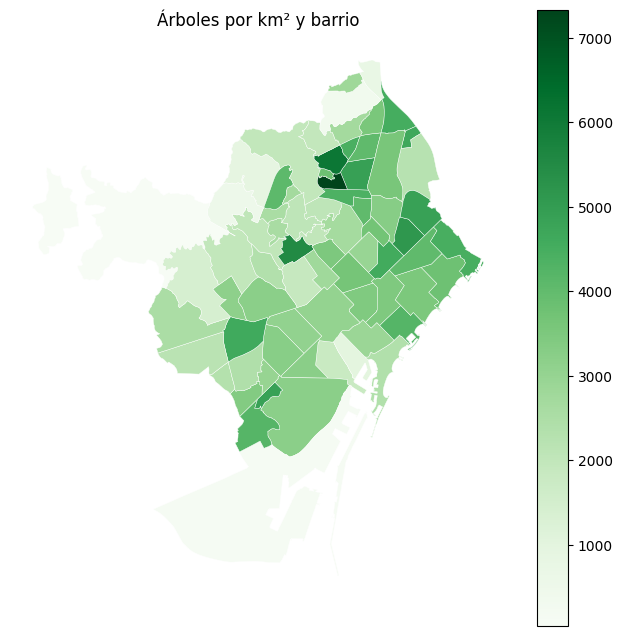

In [68]:
mapa = barrios.merge(tabla[['codi_barri', 'arboles_por_km2']], on='codi_barri')
mapa.plot(column='arboles_por_km2', cmap='Greens', legend=True, figsize=(8, 8), edgecolor='white', linewidth=0.3)
plt.title('Árboles por km² y barrio')
plt.axis('off')
plt.show()

### 5.2 Comprobación por barrios

Tomaremos como ejemplo el Barri Gòtic para compararlo con el resto

In [69]:
display(tabla[tabla['nom_districte'] == 'Ciutat Vella'][['nom_barri', 'n_arboles', 'n_palmeras', 'arboles_por_km2']].round(1))
print('Mediana de la ciudad (árboles por km²):', round(tabla['arboles_por_km2'].median(), 0))

,nom_barri,n_arboles,n_palmeras,arboles_por_km2
0,el Raval,2009,123,1825.9
1,el Barri Gòtic,797,185,977.2
2,la Barceloneta,2825,583,2395.3
3,"Sant Pere, Santa Caterina i la Ribera",3227,321,2908.1


Mediana de la ciudad (árboles por km²): 3156.0


## 6. Guardamos la tabla por barrio

In [70]:
salida = tabla.drop(columns=['nom_barri', 'nom_districte', 'area_km2', 'posicion_total', 'posicion_calle'])
salida.to_csv(PROCESSED + 'arbolado_por_barrio.csv', index=False, encoding='utf-8-sig')
print('Guardado:', salida.shape)

Guardado: (73, 28)
